In [311]:
#!pip install ipywidgets

In [312]:
#!pip install longstaff-schwartz

In [313]:
import numpy as np
from numpy.random import RandomState
from numpy.polynomial import Polynomial
from matplotlib import pyplot as plt
from ipywidgets import interact, IntSlider
from scipy.stats.distributions import lognorm, rv_frozen
from pathlib import Path

In [314]:
class GeometricBrownianMotion:
    """Geometric Brownian Motion.(with optional drift)."""

    def __init__(self, mu: float = 0.0, sigma: float = 1.0):
        self.mu = mu
        self.sigma = sigma

    def simulate(self, t: np.array, n: int, rnd: np.random.RandomState) -> np.ndarray:
        assert t.ndim == 1, "One dimensional time vector required"
        assert t.size > 0, "At least one time point is required"
        dt = np.concatenate((t[0:1], np.diff(t)))
        assert (dt >= 0).all(), "Increasing time vector required"
        # transposed simulation for automatic broadcasting
        dW = (rnd.normal(size=(t.size, n)).T * np.sqrt(dt)).T          #génère 60×50 nombres gaussiens car haque valeur représente un choc aléatoire.
        W = np.cumsum(dW, axis=0)
        return np.exp(self.sigma * W.T + (self.mu - self.sigma**2 / 2) * t).T

    def distribution(self, t: float) -> rv_frozen:
        mu_t = (self.mu - self.sigma**2 / 2) * t
        sigma_t = self.sigma * np.sqrt(t)
        return lognorm(scale=np.exp(mu_t), s=sigma_t)

In [315]:
use_test_data = False # → Petit dataset, résultats connus
svg_out_path = None  # Path('img') # Désactive la sauvegarde

if svg_out_path:
    svg_out_path.mkdir(parents=True, exist_ok=True)  # sauvegarder des graphiques au format SVG 

if use_test_data:
    t = np.linspace(0, 3, 4)
    r = 0.06 # Taux sans risque
    X = np.array(
        [
            [1.00, 1.09, 1.08, 1.34],
            [1.00, 1.16, 1.26, 1.54],
            [1.00, 1.22, 1.07, 1.03],
            [1.00, 0.93, 0.97, 0.92],
            [1.00, 1.11, 1.56, 1.52],
            [1.00, 0.76, 0.77, 0.90],
            [1.00, 0.92, 0.84, 1.01],
            [1.00, 0.88, 1.22, 1.34],
        ]
    ).T
else:
    r = 0.02
    sigma = 0.15
    gbm = GeometricBrownianMotion(mu=r, sigma=sigma)
    t = np.linspace(0, 5, 12 * 5)  # 60 points sur 5 ans
    rnd = RandomState(seed=1234)
    X = gbm.simulate(t, 50, rnd)  # 50 trajectoires ( monte-carlo )

X.shape

(60, 50)

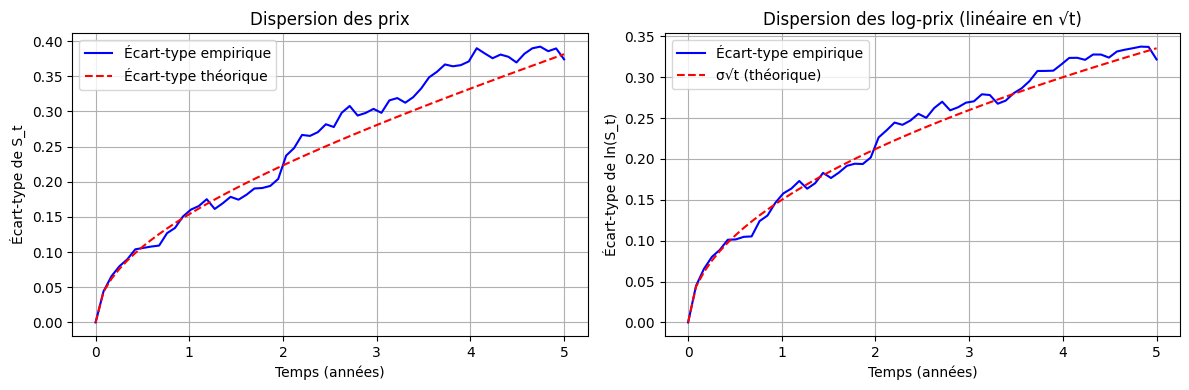

In [316]:
# Calcul de l'écart-type empirique au cours du temps
S0 = 1
std_empirique = np.std(X, axis=1)
std_theorique = S0 * np.sqrt(np.exp(2*r*t)*(np.exp(sigma**2*t)-1))

# Alternative pour le log-prix
log_std_empirique = np.std(np.log(X), axis=1)
log_std_theorique = sigma * np.sqrt(t)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(t, std_empirique, 'b-', label='Écart-type empirique')
axes[0].plot(t, std_theorique, 'r--', label='Écart-type théorique')
axes[0].set_xlabel('Temps (années)')
axes[0].set_ylabel('Écart-type de S_t')
axes[0].set_title('Dispersion des prix')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(t, log_std_empirique, 'b-', label='Écart-type empirique')
axes[1].plot(t, log_std_theorique, 'r--', label='σ√t (théorique)')
axes[1].set_xlabel('Temps (années)')
axes[1].set_ylabel('Écart-type de ln(S_t)')
axes[1].set_title('Dispersion des log-prix (linéaire en √t)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [317]:
figsize = (8, 6)

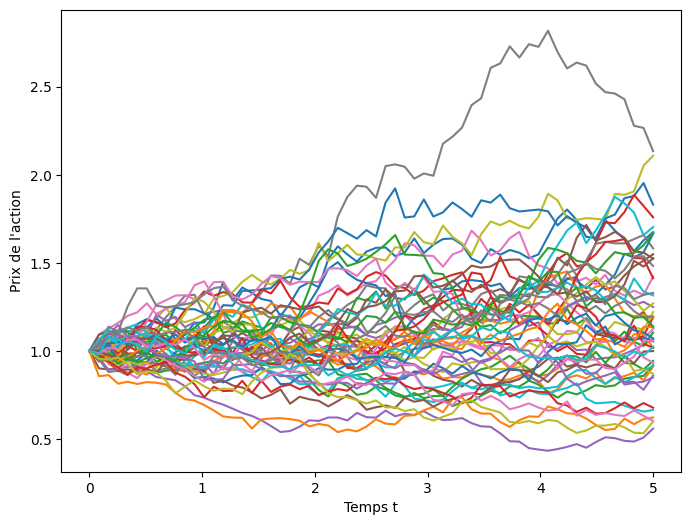

In [318]:
plt.figure(figsize=figsize)
plt.plot(t, X)
plt.xlabel("Temps t")
plt.ylabel("Prix de l'action")

if svg_out_path:
    plt.savefig(svg_out_path / "monte-carlo.svg")

In [319]:
def exercise_value(s):
    return np.maximum(1.1 - s, 0)

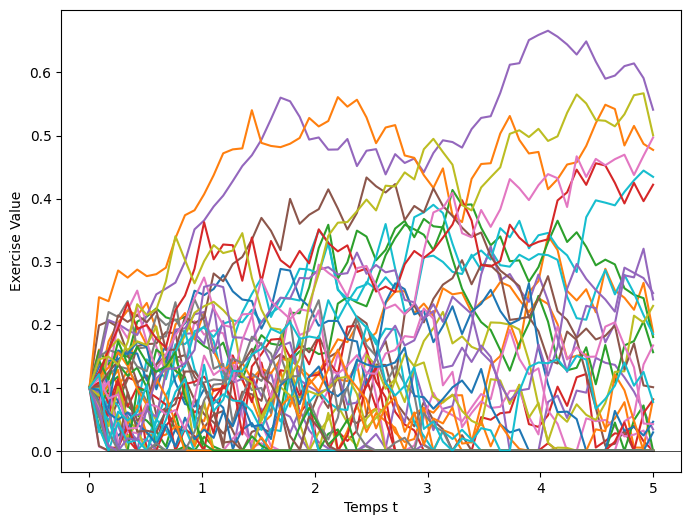

In [320]:
plt.figure(figsize=figsize)
plt.plot(t, exercise_value(X))
plt.xlabel("Temps t")
plt.ylabel("Exercise Value")
# Ajouter une ligne horizontale à 0 pour référence
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
if svg_out_path:
    plt.savefig(svg_out_path / "exercise-value.svg")

In [321]:
cashflow = exercise_value(X[-1, :]) * np.exp(-r * (t[-1] - t[-1]))
p = Polynomial.fit(X[-2, :], cashflow, 2) # ajuster un polynôme de degré 2
p

Polynomial([-0.03278163, -0.19029945,  0.36102738], domain=[0.50897487, 2.26567723], window=[-1.,  1.], symbol='x')

In [322]:
#plt.title("Valeur des flux futurs actualisés à t=4")


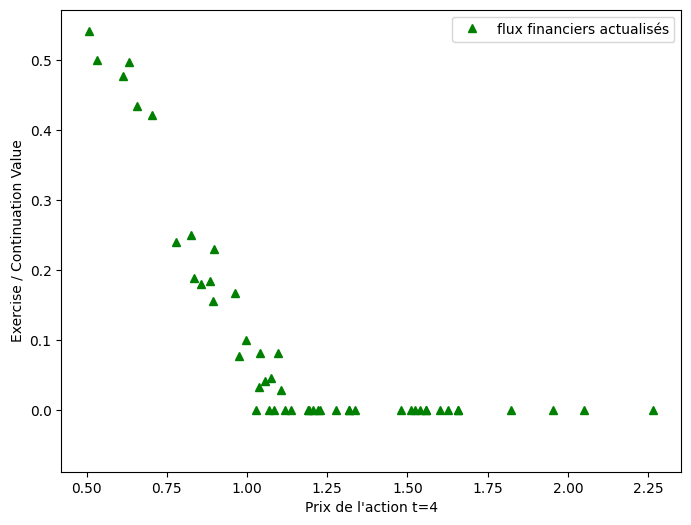

In [323]:
plt.figure(figsize=figsize)
plt.plot(X[-2, :], cashflow, "g^", zorder=3)
plt.legend(["flux financiers actualisés"])
plt.xlabel("Prix de l'action t=4")
plt.ylabel("Exercise / Continuation Value")
plt.ylim((-0.08791336286787135, 0.5718020055206748))

if svg_out_path:
    plt.savefig(svg_out_path / "continuation-value-cashflows.svg")

In [324]:
# Normalement, tous les cashflows devraient être ≥ 0
print(f"Cashflow min: {np.min(cashflow)}")
print(f"Nombre de valeurs négatives: {np.sum(cashflow < 0)}")

Cashflow min: 0.0
Nombre de valeurs négatives: 0


In [325]:
#plt.title("Estimation de la valeur de continuation à t=4")

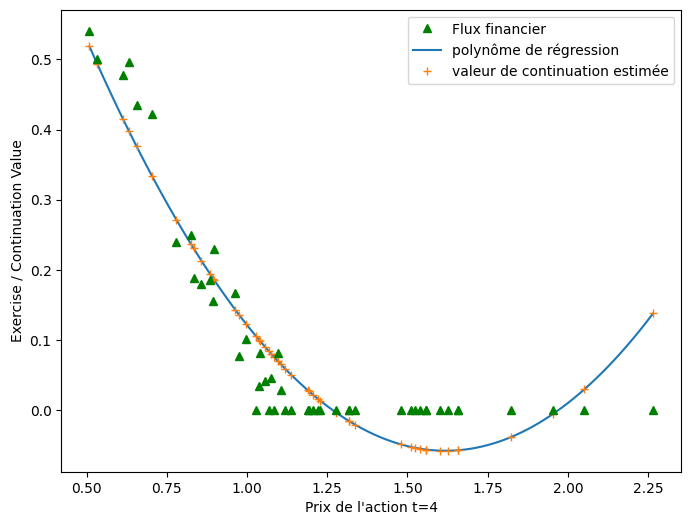

In [326]:
plt.figure(figsize=figsize)
plt.plot(X[-2, :], cashflow, "g^", zorder=3)
plt.plot(*p.linspace(), zorder=1)
plt.plot(X[-2, :], p(X[-2, :]), "+", zorder=2)
plt.legend(
    ["Flux financier", "polynôme de régression", "valeur de continuation estimée"]
)
plt.xlabel("Prix de l'action t=4")
plt.ylabel("Exercise / Continuation Value")

if svg_out_path:
    plt.savefig(svg_out_path / "continuation-value-approximation.svg")

In [327]:
intermediate_results = []

cashflow = exercise_value(X[-1, :])  # Initialisation
# iterating backwards in time
for i in reversed(range(1, X.shape[0] - 1)):                   #On remonte dans le temps : de T−1 vers 1
    df = np.exp(-r * (t[i + 1] - t[i]))  # Cette boucle parcourt les instants de T-1 jusqu'à 1 (pas jusqu'à 0)   # X.shape[0] = 60
                                                                                                                # range(1, 59) = [1, 2, 3, ..., 58]
                                                                                                                # reversed = [58, 57, ..., 3, 2, 1]
    # discount cashflows from next period
    cashflow = cashflow * df                  #df = np.exp(-r * (t[i + 1] - t[i]))
                                              # cashflow = cashflow * df 
                                              # Valeur à t[i] = Valeur à t[i+1] × e^(-r × dt) 
    x = X[i, :]                   # Prix du sous-jacent à t[i] pour toutes les trajectoires
    # boolean index of all in-the-money paths
    itm = exercise_value(x) > 0                                 #On ne fait la régression que sur les trajectoires où exercer maintenant rapporterait quelque chose
    # fit polynomial of degree 2
    fitted = Polynomial.fit(x[itm], cashflow[itm], 2)
    # approximate continuation value
    continuation = fitted(x)
    # exercise value for time t[i]
    exercise = exercise_value(x)
    # boolean index where exercise is beneficial
    ex_idx = itm & (exercise > continuation)
    # update cashflows with early exercises
    cashflow[ex_idx] = exercise[ex_idx]         # Pour les trajectoires où on exerce, on remplace le cashflow futur par le payoff immédiat.

    intermediate_results.append((cashflow, x, fitted, continuation, exercise, ex_idx))

In [328]:
# trouve le minimum global et le maximum global
def running_min_max(*array_seq):
    minimum, maximum = None, None
    for a in array_seq:
        cmin, cmax = a.min(), a.max()
        if minimum is None or cmin < minimum:
            minimum = cmin
        if maximum is None or cmax > maximum:
            maximum = cmax
    return minimum, maximum

In [329]:
grey ="#dddddd"


def plot_approx_n(n_steps, ax):
    cashflow, x, fitted, continuation, exercise, ex_idx = intermediate_results[n_steps]
    fitted_x, fitted_y = fitted.linspace()
    y_min, y_max = running_min_max(cashflow, exercise, fitted_y)
    offset = 0.1 * (y_max - y_min)
    ax.set_ylim((y_min - offset, y_max + offset))
    ax.plot(x, cashflow, "^", color="green", zorder=3)
    ax.plot(x[ex_idx], exercise[ex_idx], "x", color="red", zorder=5)
    ax.plot(x[~ex_idx], exercise[~ex_idx], "x", color=grey, zorder=4)
    ax.plot(fitted_x, fitted_y, zorder=2)
    _x = np.linspace(np.min(x), np.max(x))
    ax.plot(_x, fitted(_x), "--", color=grey, zorder=1)
    ax.legend(
        [
            "Cashflows actualisés",
            "Exercices favorables ",
            "Exercices défavorables",
            "Valeur de continuation estimée par régression",
            "Extrapolation hors zone (moins fiable)",
        ]
    )

In [330]:
@interact(n_steps=IntSlider(min=0, max=len(intermediate_results) - 1, value=14)) # Curseur que vous pouvez déplacer
def step(n_steps):
    fig, ax = plt.subplots()
    fig.set_figwidth(figsize[0])
    fig.set_figheight(figsize[1])
    plot_approx_n(n_steps, ax)
    plt.xlabel("Stock Price")
    plt.ylabel("Exercise / Continuation Value")

interactive(children=(IntSlider(value=14, description='n_steps', max=57), Output()), _dom_classes=('widget-int…

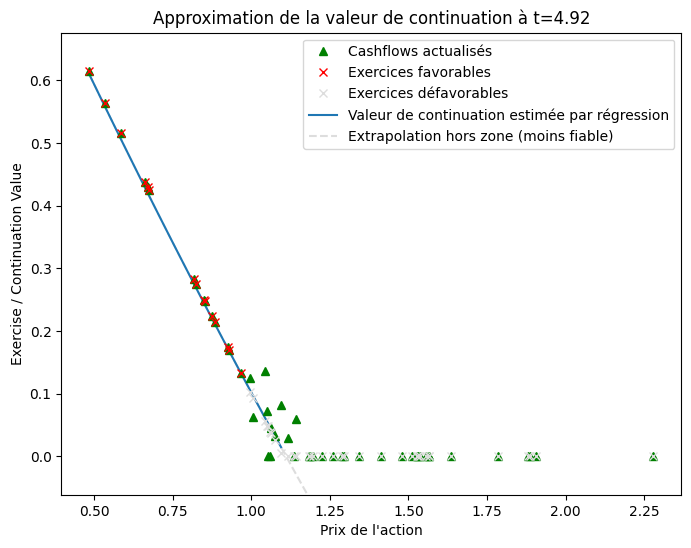

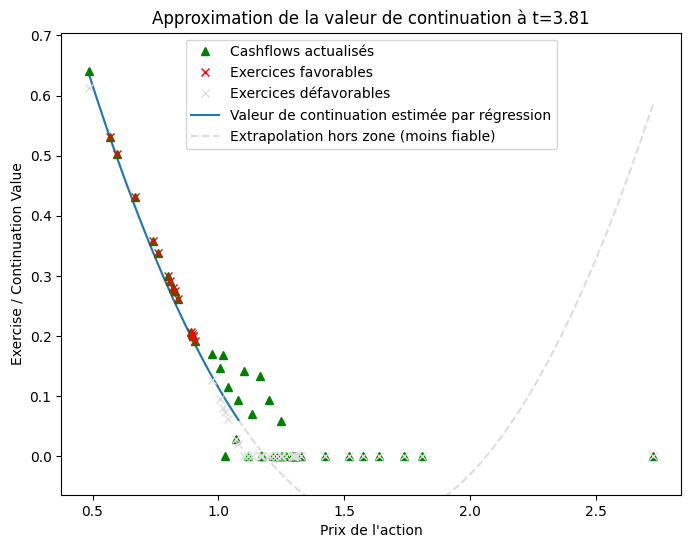

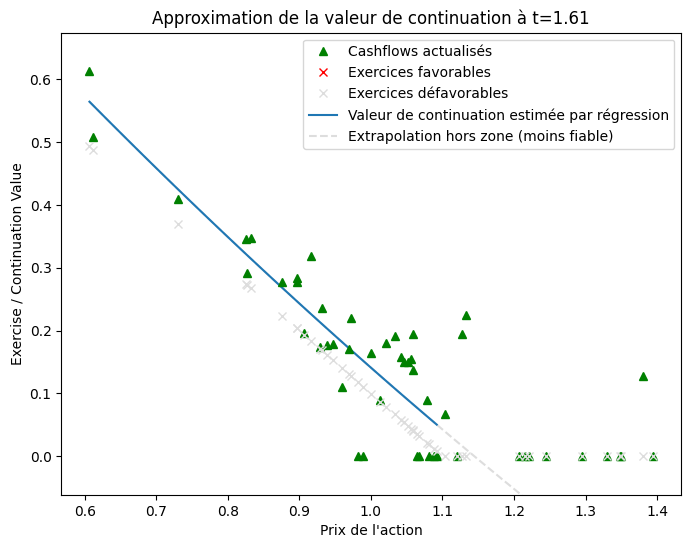

In [331]:
indices = [0, 1] if use_test_data else [1, 14, 40]

for n, i in enumerate(indices):
    fig, ax = plt.subplots()
    fig.set_figwidth(figsize[0])
    fig.set_figheight(figsize[1])
    plot_approx_n(i, ax)
    ax.set_title(f"Approximation de la valeur de continuation à t={t[-i-1]:0.2f}")
    plt.xlabel("Prix de l'action")
    plt.ylabel("Exercise / Continuation Value")

    if svg_out_path:
        plt.savefig(
            svg_out_path / f"approximated-continuation-and-exercise-value-{n}.svg"
        )

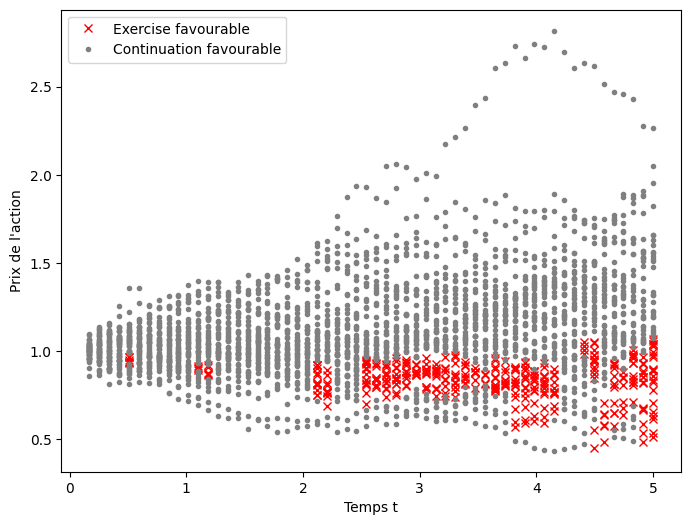

In [332]:
exercise_times = []
exercises = []
non_exercise_times = []
non_exercises = []
for i, (cashflow, x, fitted, continuation, exercise, ex_idx) in enumerate(
    intermediate_results
):
    for ex in x[ex_idx]:
        exercise_times.append(t[-i - 1])
        exercises.append(ex)
    for ex in x[~ex_idx]:
        non_exercise_times.append(t[-i - 1])
        non_exercises.append(ex)

plt.figure(figsize=figsize)
plt.plot(exercise_times, exercises, "rx")
plt.plot(non_exercise_times, non_exercises, ".", color="grey")
plt.legend(["Exercise favourable", "Continuation favourable"])
plt.xlabel("Temps t")
plt.ylabel("Prix de l'action")

if svg_out_path:
    plt.savefig(svg_out_path / "exercise-or-hold.svg")

On peut imaginer une courbe implicite qui sépare :

zone haute → continuation
zone basse → exercice

✔️ Cette courbe est :

décroissante dans le temps
dépend du prix critique S
∗
(t)

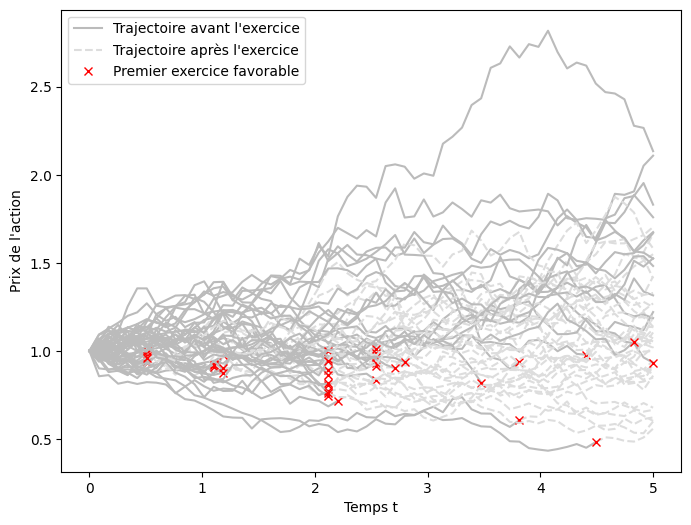

In [333]:
n_timesteps, n_paths = X.shape
first_exercise_idx = n_timesteps * np.ones(shape=(n_paths,), dtype="int")
for i, (cashflow, x, fitted, continuation, exercise, ex_idx) in enumerate(
    intermediate_results
):
    for ex in x[ex_idx]:
        idx_now = (n_timesteps - i - 1) * np.ones(shape=(n_paths,), dtype="int")
        first_exercise_idx[ex_idx] = idx_now[ex_idx]

plt.figure(figsize=figsize)
for i in range(n_paths):
    (handle_path,) = plt.plot(
        t[0 : first_exercise_idx[i] + 1],
        X[0 : first_exercise_idx[i] + 1, i],
        "-",
        color="#bbbbbb",
    )
    (handle_stopped_path,) = plt.plot(
        t[first_exercise_idx[i] :], X[first_exercise_idx[i] :, i], "--", color=grey
    )
    if first_exercise_idx[i] < n_timesteps:
        (handle_first_ex,) = plt.plot(
            t[first_exercise_idx[i]], X[first_exercise_idx[i], i], "rx"
        )

plt.legend(
    [handle_path, handle_stopped_path, handle_first_ex],
    ["Trajectoire avant l'exercice", "Trajectoire après l'exercice", "Premier exercice favorable"],
)
plt.xlabel("Temps t")
plt.ylabel("Prix de l'action")

if svg_out_path:
    plt.savefig(svg_out_path / "first-exercises.svg")

Polynomial([ 0.69626078, -0.10168727, -0.10963723], domain=[0.50847458, 5.        ], window=[-1.,  1.], symbol='x')

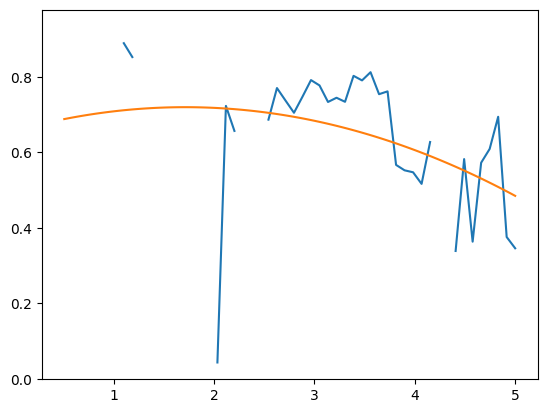

In [334]:
ex_times = []
ex_boundary = []
for i, (cashflow, x, fitted, continuation, exercise, ex_idx) in enumerate(
    intermediate_results
):
    fitted = fitted.convert(domain=[-1, 1], window=[-1, 1])
    to_solve = fitted - Polynomial([1.1, -1])
    roots = to_solve.roots()
    roots = [root for root in roots if root <= 1.1 and root >= 0 and root.imag == 0.0]
    if roots:
        ex_boundary.append(min(roots))
    else:
        ex_boundary.append(None)
    ex_times.append(t[-i - 1])

ex_boundary = np.array(ex_boundary, dtype="float")
ex_times = np.array(ex_times)
fitted_boundary = Polynomial.fit(
    ex_times[~np.isnan(ex_boundary)], ex_boundary[~np.isnan(ex_boundary)], 2
)
plt.plot(ex_times, ex_boundary)
plt.plot(*fitted_boundary.linspace())
fitted_boundary


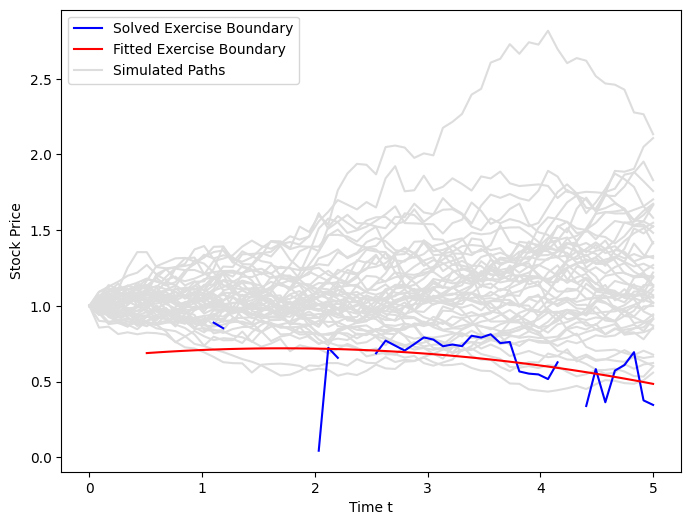

In [335]:
plt.figure(figsize=figsize)
plt.plot(ex_times, ex_boundary, color="blue", zorder=2)
plt.plot(*fitted_boundary.linspace(), "r", zorder=3)
plt.plot(t, X, color="#dddddd", zorder=1)
plt.legend(["Solved Exercise Boundary", "Fitted Exercise Boundary", "Simulated Paths"])
plt.xlabel("Time t")
plt.ylabel("Stock Price")

if svg_out_path:
    plt.savefig(svg_out_path / "fitted-exercise-boundary.svg")

In [336]:
df = np.exp(-r * (t[1] - t[0]))
cashflow = cashflow * df
european_cashflow = exercise_value(X[-1, :]) * np.exp(-r * (t[-1] - t[0]))
assert np.average(cashflow) >= np.average(european_cashflow)
print(np.round(np.average(cashflow), 4))
print(np.round(np.average(european_cashflow), 4))

0.1612
0.0898


In [337]:
from longstaff_schwartz.algorithm import longstaff_schwartz
from longstaff_schwartz.stochastic_process import GeometricBrownianMotion
import numpy as np

# Model parameters
t = np.linspace(0, 5, 100)  # timegrid for simulation
r = 0.01  # riskless rate
sigma = 0.15  # annual volatility of underlying
n = 100  # number of simulated paths

# Simulate the underlying
gbm = GeometricBrownianMotion(mu=r, sigma=sigma)
rnd = np.random.RandomState(1234)
x = gbm.simulate(t, n, rnd)  # x.shape == (t.size, n)

# Payoff (exercise) function
strike = 0.95

def put_payoff(spot):
    return np.maximum(strike - spot, 0.0)

# Discount factor function
def constant_rate_df(t_from, t_to):
    return np.exp(-r * (t_to - t_from))

# Approximation of continuation value
def fit_quadratic(x, y):
    return np.polynomial.Polynomial.fit(x, y, 2, rcond=None)

# Selection of paths to consider for exercise
# (and continuation value approxmation)
def itm(payoff, spot):
    return payoff > 0

# Run valuation of American put option
npv_american = longstaff_schwartz(x, t, constant_rate_df,
                                  fit_quadratic, put_payoff, itm)

# European put option for comparison
npv_european = constant_rate_df(t[0], t[-1]) * put_payoff(x[-1]).mean()

# Check results
assert np.round(npv_american, 4) == 0.0734
assert np.round(npv_european, 4) == 0.0626
assert npv_american > npv_european